# Defining variables: time of day and weather quartiles

This notebook creates the first derived variables for modelling electricity use:

1. **Time of day**: each hour is assigned to night, morning, afternoon or evening.
2. **Weather quartiles**: within each time of day, each hour's temperature, humidity and windspeed is ranked into quartiles (Q1 = lowest 25%, Q4 = highest 25%).

It then uses box plots to show how hourly electricity use changes across those weather quartiles, for all customers and for the known **EV**, **heat pump (HP)** and **solar PV** customers.

Data comes from `avangrid.db`, built in parts 1 and 2:

- **`ami_analysis`**: hourly meter data for the 25,156 customers with a full year of data (short gaps imputed, still-incomplete customers dropped);
- **`weather`**: hourly weather, joinable to the meter data on `usage_date` and `hour_ending`.

Run this notebook from the project folder, the one containing `onedrive-export/`.

## Setup

In [1]:
import os

import duckdb
import matplotlib.pyplot as plt
import polars as pl

DB_PATH = 'onedrive-export/Data/avangrid.db'
CUSTOMER_GROUPS_PATH = 'onedrive-export/Data/EV_Heat Pump_Solar PV Customers.xlsx'
PLOT_DIR = 'onedrive-export/Data/eda/boxplots'
os.makedirs(PLOT_DIR, exist_ok=True)

con = duckdb.connect(DB_PATH)
con.execute('SET enable_progress_bar = false')  # keep notebook output clean

## Define time of day

The day is split into four 6-hour blocks:

| Time of day | Clock time | `hour_ending` |
|---|---|---|
| night | 12:00 am – 5:59 am | 1–6 |
| morning | 6:00 am – 11:59 am | 7–12 |
| afternoon | 12:00 pm – 5:59 pm | 13–18 |
| evening | 6:00 pm – 11:59 pm | 19–24 |

`hour_ending` labels each hour by when it **ends**, so `hour_ending` 1 is 12:00–12:59 am and `hour_ending` 6 is 5:00–5:59 am. That's why night is `hour_ending` 1–6, not 0–5.

These blocks group hours with similar electricity use: overnight base load, morning routines, daytime (when solar panels generate) and the evening peak. That makes weather effects easier to compare than across 24 separate hours.

The rule is stored once in DuckDB as a macro, `time_of_day(hour_ending)`, so every query and later notebook uses exactly the same definition.

In [2]:
TIME_OF_DAY_ORDER = ['night', 'morning', 'afternoon', 'evening']
TIME_OF_DAY_LABELS = {
    'night': 'Night (12 am – 5:59 am)',
    'morning': 'Morning (6 am – 11:59 am)',
    'afternoon': 'Afternoon (12 pm – 5:59 pm)',
    'evening': 'Evening (6 pm – 11:59 pm)',
}

con.execute('''
    CREATE OR REPLACE MACRO time_of_day(hour_ending) AS
        CASE WHEN hour_ending <= 6  THEN 'night'
             WHEN hour_ending <= 12 THEN 'morning'
             WHEN hour_ending <= 18 THEN 'afternoon'
             ELSE 'evening' END
''')

con.sql('''
    SELECT time_of_day(hour_ending) AS time_of_day,
           MIN(hour_ending) AS first_hour_ending,
           MAX(hour_ending) AS last_hour_ending
    FROM range(1, 25) t(hour_ending)
    GROUP BY 1 ORDER BY 2
''').pl()

time_of_day,first_hour_ending,last_hour_ending
str,i64,i64
"""night""",1,6
"""morning""",7,12
"""afternoon""",13,18
"""evening""",19,24


## Weather quartiles within each time of day

For each time of day and each weather column (`temp`, `humidity`, `windspeed`), we find the 25th, 50th (median) and 75th percentiles across all hours in the year. Each hour is then placed in a quartile:

| Quartile | Rule |
|---|---|
| Q1 | value ≤ 25th percentile |
| Q2 | 25th < value ≤ median |
| Q3 | median < value ≤ 75th percentile |
| Q4 | value > 75th percentile |

**Why within each time of day?** Nights are colder than afternoons. Quartiles based on all hours together would put almost every night hour in the low temperature quartiles and every afternoon hour in the high ones, so "temperature" would mostly be measuring "time of day". Ranking hours *against other hours at the same time of day* separates the effect of an unusually cold or warm night from the normal daily cycle.

Hours with a missing weather value (about 94 hours, depending on the column) get no quartile for that column and are left out of its plots.

The result is saved to DuckDB as **`weather_features`**: one row per date and hour, with `time_of_day` and a quartile column for each weather variable. It joins to `ami_analysis` on `usage_date` and `hour_ending`, so these variables can be reused in later notebooks.

In [3]:
WEATHER_VARS = {
    'temp': 'Temperature (°F)',
    'humidity': 'Humidity (%)',
    'windspeed': 'Windspeed',
}

def quartile_case(col: str) -> str:
    return f'''
        CASE WHEN w.{col} IS NULL THEN NULL
             WHEN w.{col} <= c.{col}_cuts[1] THEN 1
             WHEN w.{col} <= c.{col}_cuts[2] THEN 2
             WHEN w.{col} <= c.{col}_cuts[3] THEN 3
             ELSE 4 END::TINYINT AS {col}_quartile'''

con.execute(f'''
    CREATE OR REPLACE TABLE weather_features AS
    WITH w AS (
        SELECT *, time_of_day(hour_ending) AS time_of_day FROM weather
    ),
    c AS (
        SELECT time_of_day,
               {', '.join(f'quantile_cont({v}, [0.25, 0.5, 0.75]) AS {v}_cuts' for v in WEATHER_VARS)}
        FROM w GROUP BY time_of_day
    )
    SELECT w.usage_date, w.hour_ending, w.time_of_day,
           {', '.join(f'w.{v}' for v in WEATHER_VARS)},
           {', '.join(quartile_case(v) for v in WEATHER_VARS)}
    FROM w JOIN c USING (time_of_day)
    ORDER BY w.usage_date, w.hour_ending
''')

con.sql('SELECT * FROM weather_features LIMIT 5').pl()

usage_date,hour_ending,time_of_day,temp,humidity,windspeed,temp_quartile,humidity_quartile,windspeed_quartile
date,i8,str,f64,f64,f64,i8,i8,i8
2025-09-01,1,"""night""",56.8,72.0,8.0,3,2,3
2025-09-01,2,"""night""",55.0,74.29,4.6,3,2,1
2025-09-01,3,"""night""",53.1,79.8,4.7,3,2,2
2025-09-01,4,"""night""",53.1,82.56,4.6,3,3,1
2025-09-01,5,"""night""",53.1,79.84,4.6,3,2,1


### Quartile boundaries

The table below lists the range of each quartile, for each weather variable and time of day. These ranges are also used to label the box plots. Q1 runs from the minimum to the 25th percentile, Q4 from the 75th percentile to the maximum.

In [4]:
quartile_ranges = pl.concat([
    con.sql(f'''
        SELECT '{v}' AS variable, time_of_day, {v}_quartile AS quartile,
               MIN({v}) AS low, MAX({v}) AS high, COUNT(*) AS hours
        FROM weather_features
        WHERE {v}_quartile IS NOT NULL
        GROUP BY ALL
    ''').pl()
    for v in WEATHER_VARS
]).sort(
    pl.col('variable').cast(pl.Enum(list(WEATHER_VARS))),
    pl.col('time_of_day').cast(pl.Enum(TIME_OF_DAY_ORDER)),
    'quartile',
)

with pl.Config(tbl_rows=-1, tbl_hide_dataframe_shape=True):
    print(quartile_ranges)

┌───────────┬─────────────┬──────────┬───────┬───────┬───────┐
│ variable  ┆ time_of_day ┆ quartile ┆ low   ┆ high  ┆ hours │
│ ---       ┆ ---         ┆ ---      ┆ ---   ┆ ---   ┆ ---   │
│ str       ┆ str         ┆ i8       ┆ f64   ┆ f64   ┆ i64   │
╞═══════════╪═════════════╪══════════╪═══════╪═══════╪═══════╡
│ temp      ┆ night       ┆ 1        ┆ -5.0  ┆ 29.9  ┆ 550   │
│ temp      ┆ night       ┆ 2        ┆ 30.0  ┆ 45.0  ┆ 538   │
│ temp      ┆ night       ┆ 3        ┆ 45.1  ┆ 58.9  ┆ 559   │
│ temp      ┆ night       ┆ 4        ┆ 59.9  ┆ 78.2  ┆ 519   │
│ temp      ┆ morning     ┆ 1        ┆ -5.0  ┆ 29.9  ┆ 551   │
│ temp      ┆ morning     ┆ 2        ┆ 30.0  ┆ 45.1  ┆ 544   │
│ temp      ┆ morning     ┆ 3        ┆ 45.9  ┆ 61.0  ┆ 540   │
│ temp      ┆ morning     ┆ 4        ┆ 61.1  ┆ 84.9  ┆ 531   │
│ temp      ┆ afternoon   ┆ 1        ┆ -1.9  ┆ 33.2  ┆ 567   │
│ temp      ┆ afternoon   ┆ 2        ┆ 34.0  ┆ 53.2  ┆ 522   │
│ temp      ┆ afternoon   ┆ 3        ┆ 53.3  ┆ 70.1  ┆ 

The `hours` column shows the quartiles aren't exactly equal in size. Weather values are rounded (temperature to 0.1°F, for example), so many hours share the same value. All hours with the value at a boundary fall in the same quartile, so one quartile can end up a little larger than another. With roughly 500–600 hours in every quartile, the groups are large enough to compare.

## Customer groups

The EV, HP and PV customer lists come from the same workbook used in part 2. They are loaded into DuckDB as a temporary table so the box-plot statistics can be computed there.

There is no need to filter out customers numbered 10,001–20,000 (the disregarded folder) or customers dropped for incomplete data: they aren't in `ami_analysis`, so the join leaves them out automatically. A customer on more than one list counts towards each group they're in.

In [5]:
sheets = pl.read_excel(CUSTOMER_GROUPS_PATH, sheet_id=0)
sheets.pop('Description')

customer_groups = pl.concat([
    customers.select(
        pl.col('CUSTOMER_NUMBER').cast(pl.Int32),
        pl.lit(tab.replace(' Customers', '')).alias('customer_group'),
    )
    for tab, customers in sheets.items()
])
con.register('customer_groups', customer_groups)

con.sql('''
    SELECT g.customer_group, COUNT(DISTINCT g.CUSTOMER_NUMBER) AS customers_in_analysis
    FROM customer_groups g
    SEMI JOIN (SELECT DISTINCT CUSTOMER_NUMBER FROM ami_analysis) a USING (CUSTOMER_NUMBER)
    GROUP BY 1 ORDER BY 1
''').pl()

customer_group,customers_in_analysis
str,i64
"""EV""",134
"""HP""",58
"""PV""",309


## Box-plot statistics, computed in DuckDB

A box plot summarises a distribution with five numbers:

- the **box**: from the 25th to the 75th percentile, holding the middle half of the hours;
- the **line** in the box: the median;
- the **whiskers**: extending to the most extreme values within 1.5 × the box height (the interquartile range) of the box, the standard Tukey rule;
- a **dot**: the mean, added because electricity use is skewed (a few very high hours), so the mean sits above the median.

"All customers" covers about 220 million hourly readings, far too many to load into Python and pass to matplotlib. Instead, DuckDB calculates these statistics for every combination of customer group, time of day and weather quartile, and matplotlib draws the boxes from them. The results are identical to what `plt.boxplot` would draw from the raw data.

**Outliers (points beyond the whiskers) are not drawn.** With this many readings there would be hundreds of thousands of them, piling up into a solid block that hides the boxes. Their count is shown in the statistics table instead.

In [6]:
def box_stats(variable: str) -> pl.DataFrame:
    return con.sql(f'''
        WITH base AS (
            SELECT a.CUSTOMER_NUMBER, a.hourly_kwh, w.time_of_day, w.{variable}_quartile AS quartile
            FROM ami_analysis a
            JOIN weather_features w USING (usage_date, hour_ending)
            WHERE w.{variable}_quartile IS NOT NULL
        ),
        labeled AS (
            SELECT 'All customers' AS customer_group, time_of_day, quartile, hourly_kwh FROM base
            UNION ALL
            SELECT g.customer_group, b.time_of_day, b.quartile, b.hourly_kwh
            FROM base b JOIN customer_groups g USING (CUSTOMER_NUMBER)
        ),
        stats AS (
            SELECT customer_group, time_of_day, quartile,
                   COUNT(*) AS hours,
                   AVG(hourly_kwh) AS mean,
                   quantile_cont(hourly_kwh, [0.25, 0.5, 0.75]) AS qs
            FROM labeled GROUP BY ALL
        )
        SELECT '{variable}' AS variable, s.customer_group, s.time_of_day, s.quartile,
               s.hours, s.mean,
               s.qs[1] AS q1, s.qs[2] AS median, s.qs[3] AS q3,
               MIN(l.hourly_kwh) FILTER (WHERE l.hourly_kwh >= s.qs[1] - 1.5 * (s.qs[3] - s.qs[1])) AS whisker_low,
               MAX(l.hourly_kwh) FILTER (WHERE l.hourly_kwh <= s.qs[3] + 1.5 * (s.qs[3] - s.qs[1])) AS whisker_high,
               COUNT(*) FILTER (WHERE l.hourly_kwh > s.qs[3] + 1.5 * (s.qs[3] - s.qs[1])
                                   OR l.hourly_kwh < s.qs[1] - 1.5 * (s.qs[3] - s.qs[1])) AS outliers
        FROM labeled l JOIN stats s USING (customer_group, time_of_day, quartile)
        GROUP BY ALL
    ''').pl()

stats = pl.concat([box_stats(v) for v in WEATHER_VARS])
print(f'{stats.height} boxes (3 variables x 4 times of day x 4 quartiles x 4 groups)')

with pl.Config(tbl_rows=16, tbl_cols=-1, thousands_separator=True):
    print(stats.filter(pl.col('variable') == 'temp', pl.col('time_of_day') == 'evening')
               .sort('quartile', 'customer_group'))

192 boxes (3 variables x 4 times of day x 4 quartiles x 4 groups)
shape: (16, 12)
┌────────┬────────┬────────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┐
│ variab ┆ custom ┆ time_o ┆ quart ┆ hours ┆ mean  ┆ q1    ┆ media ┆ q3    ┆ whisk ┆ whisk ┆ outli │
│ le     ┆ er_gro ┆ f_day  ┆ ile   ┆ ---   ┆ ---   ┆ ---   ┆ n     ┆ ---   ┆ er_lo ┆ er_hi ┆ ers   │
│ ---    ┆ up     ┆ ---    ┆ ---   ┆ i64   ┆ f64   ┆ f64   ┆ ---   ┆ f64   ┆ w     ┆ gh    ┆ ---   │
│ str    ┆ ---    ┆ str    ┆ i8    ┆       ┆       ┆       ┆ f64   ┆       ┆ ---   ┆ ---   ┆ i64   │
│        ┆ str    ┆        ┆       ┆       ┆       ┆       ┆       ┆       ┆ f64   ┆ f64   ┆       │
╞════════╪════════╪════════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╡
│ temp   ┆ All    ┆ evenin ┆ 1     ┆ 14,21 ┆ 1.181 ┆ 0.39  ┆ 0.724 ┆ 1.48  ┆ 0.0   ┆ 3.115 ┆ 1,080 │
│        ┆ custom ┆ g      ┆       ┆ 3,140 ┆ 234   ┆       ┆       ┆       ┆       ┆       ┆ ,307  │
│        

## Box plots: hourly kWh by weather quartile

There is one chart for each **time of day × weather variable** combination: 4 × 3 = 12 charts. In each chart:

- the **x-axis** shows the four weather quartiles for that time of day, labelled with their value range;
- each quartile has **four boxes**: all customers (grey), EV, HP and PV;
- every chart uses the **same y-axis scale**, so usage can be compared across times of day and weather variables.

The colours are the Okabe–Ito palette, chosen to be distinguishable for readers with colour-vision deficiency. "All customers" is grey because it's the reference the other groups are compared against. The legend names each group, so the charts don't rely on colour alone.

Each chart is also saved as a PNG in `onedrive-export/Data/eda/boxplots/`.

**Reading the charts:** look at how the boxes move from Q1 to Q4 within a chart. A rise from Q1 to Q4 in the temperature charts means more electricity is used in warmer hours (for example, air conditioning). A fall means more is used in colder hours (for example, electric heating, which matters especially for heat-pump customers).

In [7]:
GROUP_ORDER = ['All customers', 'EV', 'HP', 'PV']
GROUP_COLORS = {
    'All customers': '#8c8c8c',
    'EV': '#0072B2',
    'HP': '#E69F00',
    'PV': '#009E73',
}
GROUP_LABELS = {
    'All customers': 'All customers',
    'EV': 'EV customers',
    'HP': 'Heat pump customers',
    'PV': 'Solar PV customers',
}

Y_MAX = stats['whisker_high'].max() * 1.05
BOX_WIDTH = 0.18
OFFSETS = [-1.5 * BOX_WIDTH * 1.1, -0.5 * BOX_WIDTH * 1.1, 0.5 * BOX_WIDTH * 1.1, 1.5 * BOX_WIDTH * 1.1]


def quartile_label(variable: str, time_of_day: str, quartile: int) -> str:
    r = quartile_ranges.filter(
        pl.col('variable') == variable, pl.col('time_of_day') == time_of_day, pl.col('quartile') == quartile
    ).row(0, named=True)
    return f"Q{quartile}\n{r['low']:g} – {r['high']:g}"


def plot_boxes(variable: str, time_of_day: str):
    s = stats.filter(pl.col('variable') == variable, pl.col('time_of_day') == time_of_day)
    fig, ax = plt.subplots(figsize=(11, 5.5))

    for offset, group in zip(OFFSETS, GROUP_ORDER):
        g = s.filter(pl.col('customer_group') == group).sort('quartile')
        boxes = [
            {'med': r['median'], 'q1': r['q1'], 'q3': r['q3'],
             'whislo': r['whisker_low'], 'whishi': r['whisker_high'], 'mean': r['mean'],
             'fliers': []}
            for r in g.iter_rows(named=True)
        ]
        color = GROUP_COLORS[group]
        ax.bxp(
            boxes,
            positions=[q + offset for q in g['quartile']],
            widths=BOX_WIDTH,
            showfliers=False,
            showmeans=True,
            patch_artist=True,
            boxprops={'facecolor': color, 'edgecolor': color, 'alpha': 0.85},
            medianprops={'color': 'white', 'linewidth': 2},
            whiskerprops={'color': color, 'linewidth': 1.5},
            capprops={'color': color, 'linewidth': 1.5},
            meanprops={'marker': 'o', 'markerfacecolor': 'white', 'markeredgecolor': '#333333',
                       'markersize': 5},
        )
        ax.plot([], [], color=color, linewidth=8, label=GROUP_LABELS[group])

    ax.plot([], [], 'o', markerfacecolor='white', markeredgecolor='#333333', label='Mean')
    ax.set_xticks([1, 2, 3, 4], [quartile_label(variable, time_of_day, q) for q in range(1, 5)])
    ax.set_xlim(0.4, 4.6)
    ax.set_ylim(0, Y_MAX)
    ax.set_xlabel(f'{WEATHER_VARS[variable]} quartile (within {time_of_day} hours)')
    ax.set_ylabel('Hourly electricity use (kWh)')
    ax.set_title(f'Hourly kWh by {WEATHER_VARS[variable].split(" (")[0].lower()} quartile: '
                 f'{TIME_OF_DAY_LABELS[time_of_day]}')
    ax.grid(axis='y', color='#e5e5e5', linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False)
    fig.tight_layout()

    fig.savefig(f'{PLOT_DIR}/kwh_by_{variable}_quartile_{time_of_day}.png', dpi=150)
    plt.show()

### Temperature

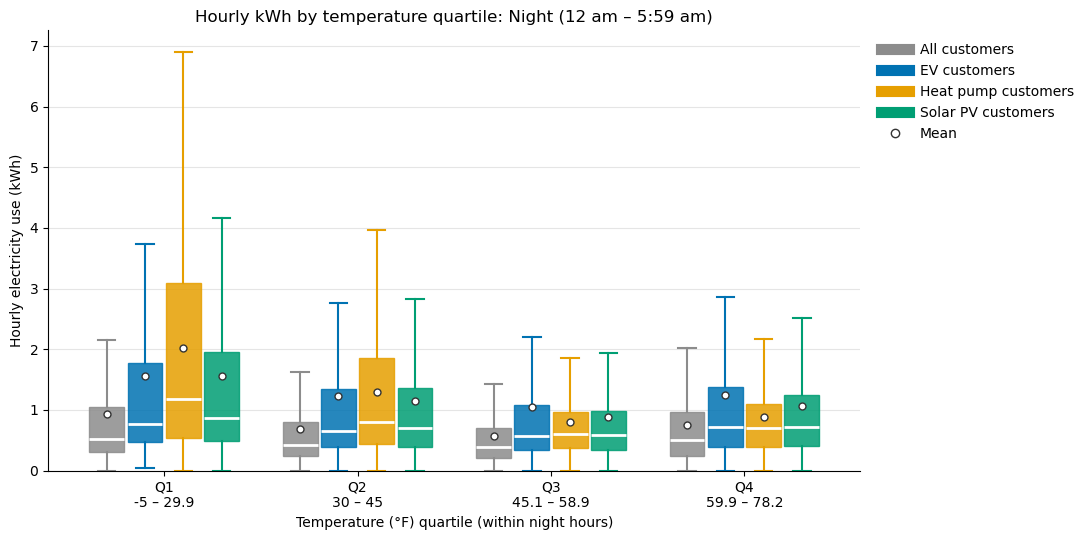

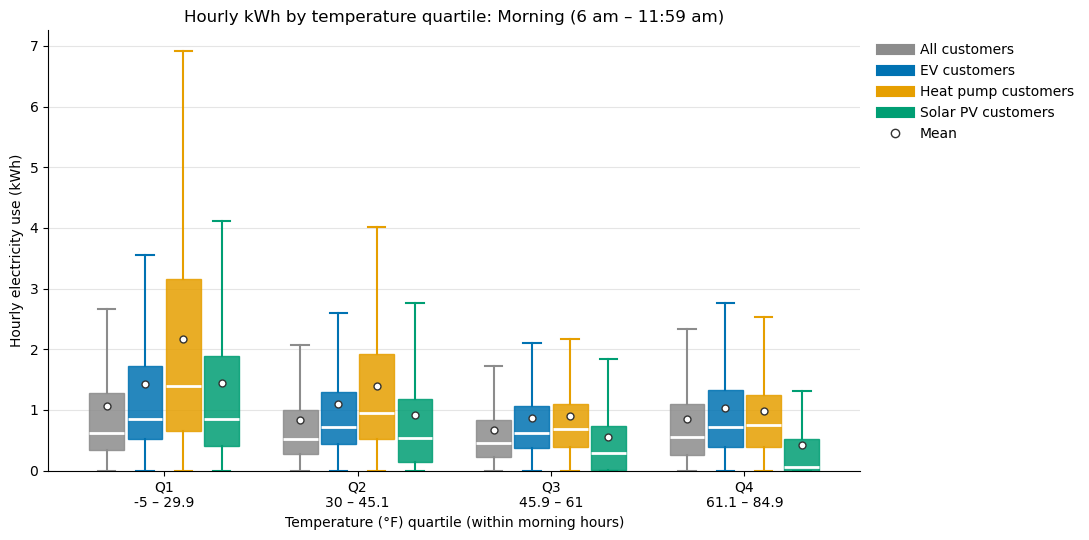

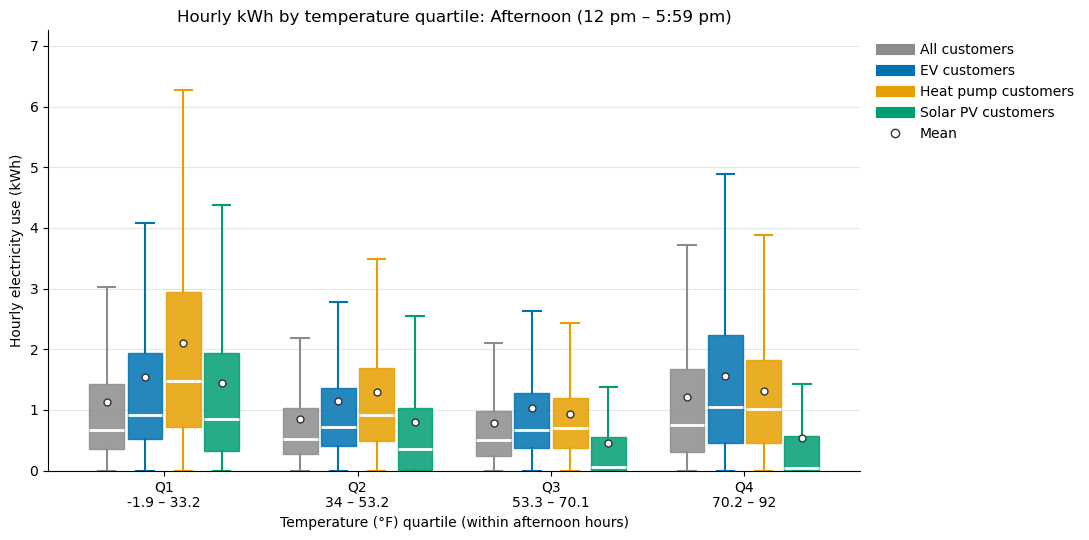

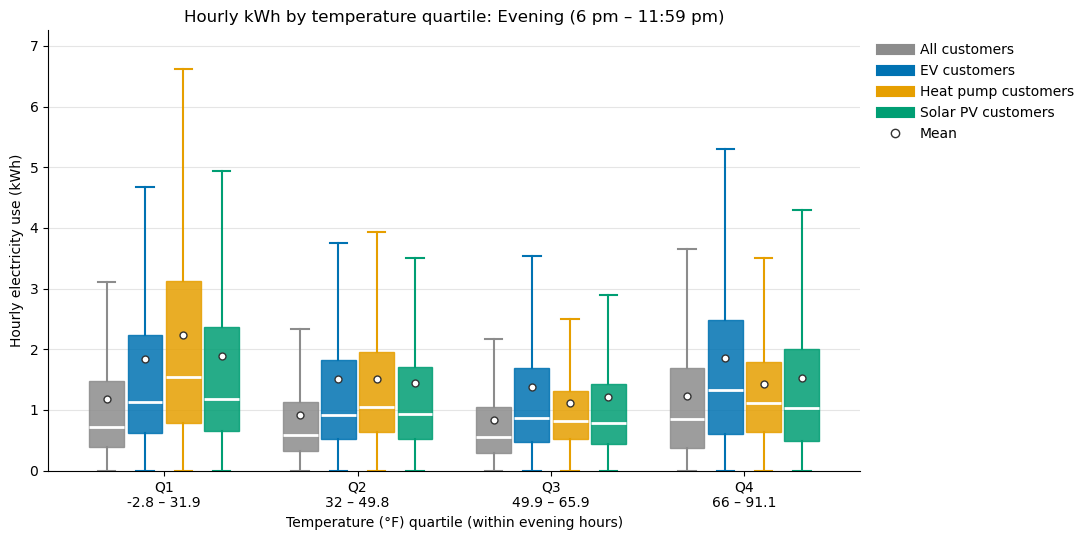

In [8]:
for time_of_day in TIME_OF_DAY_ORDER:
    plot_boxes('temp', time_of_day)

### Humidity

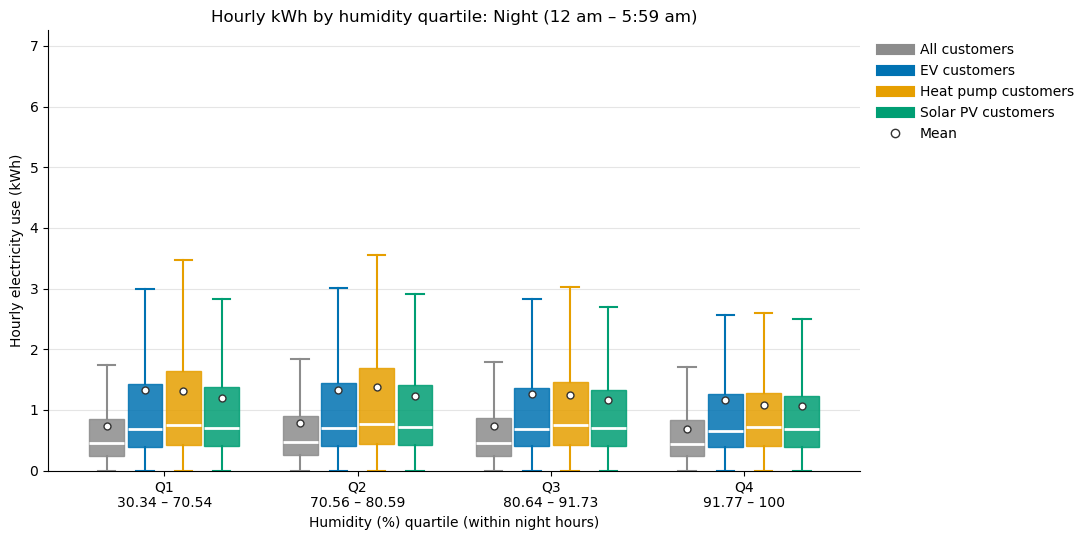

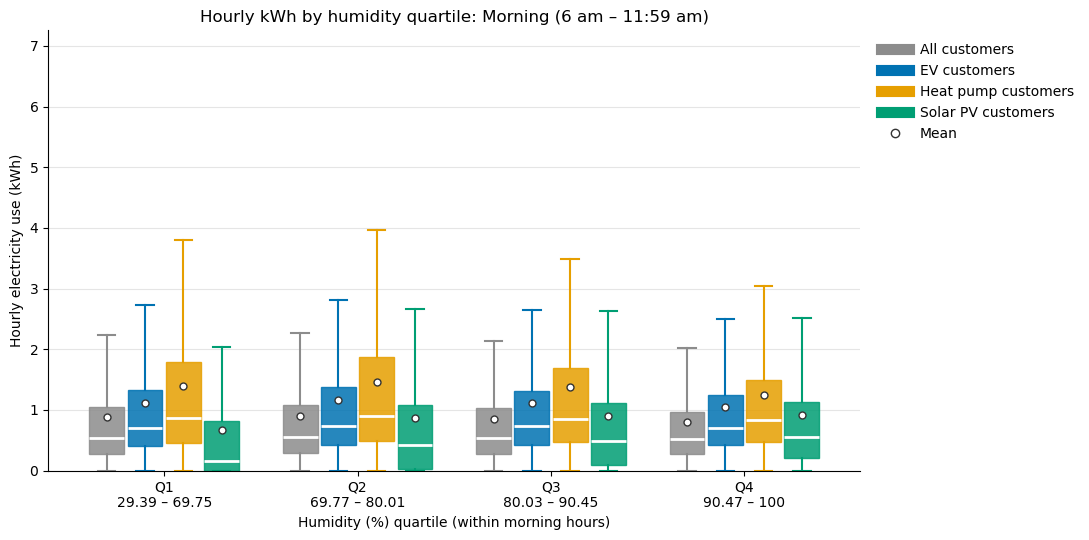

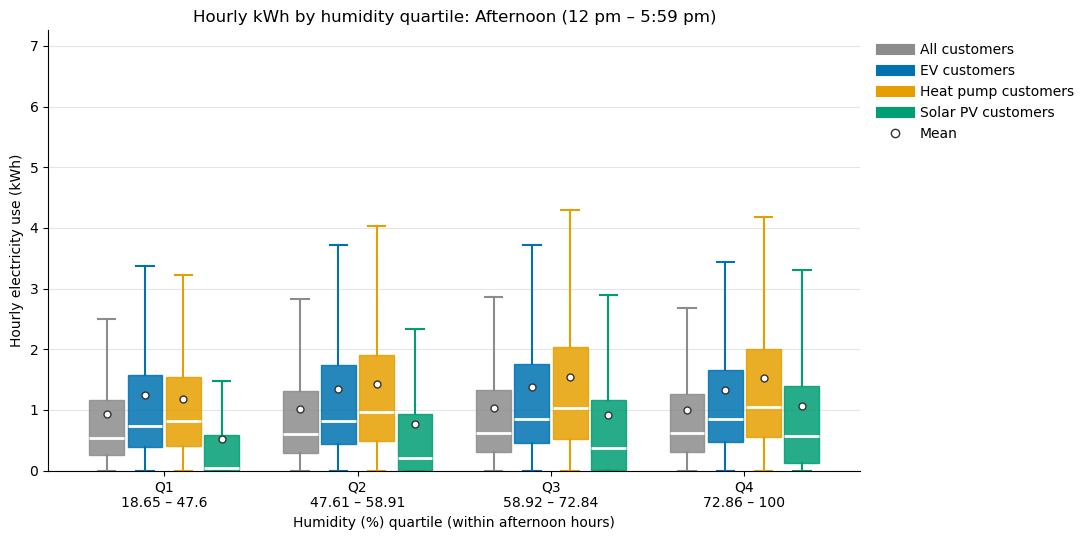

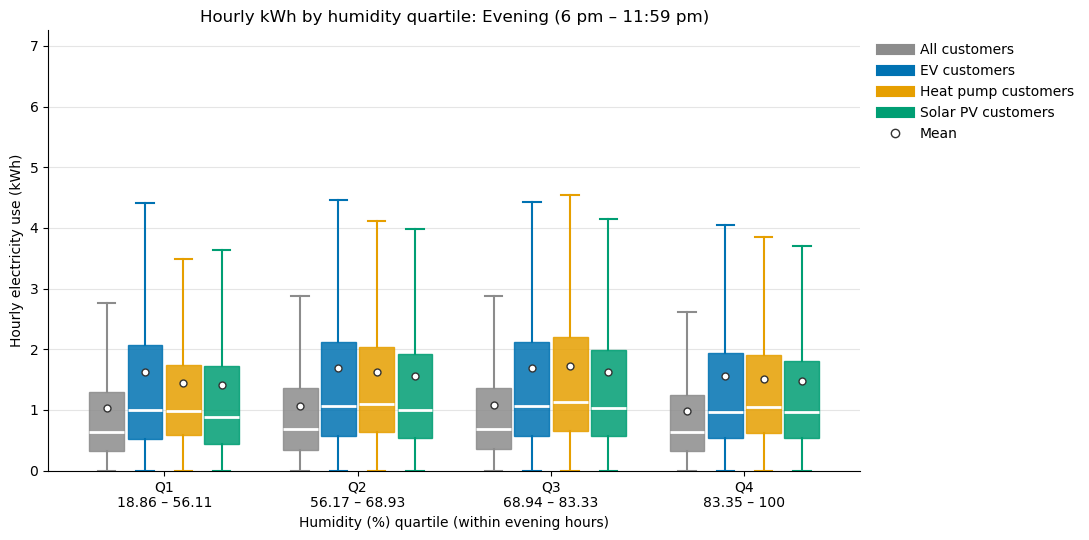

In [9]:
for time_of_day in TIME_OF_DAY_ORDER:
    plot_boxes('humidity', time_of_day)

### Windspeed

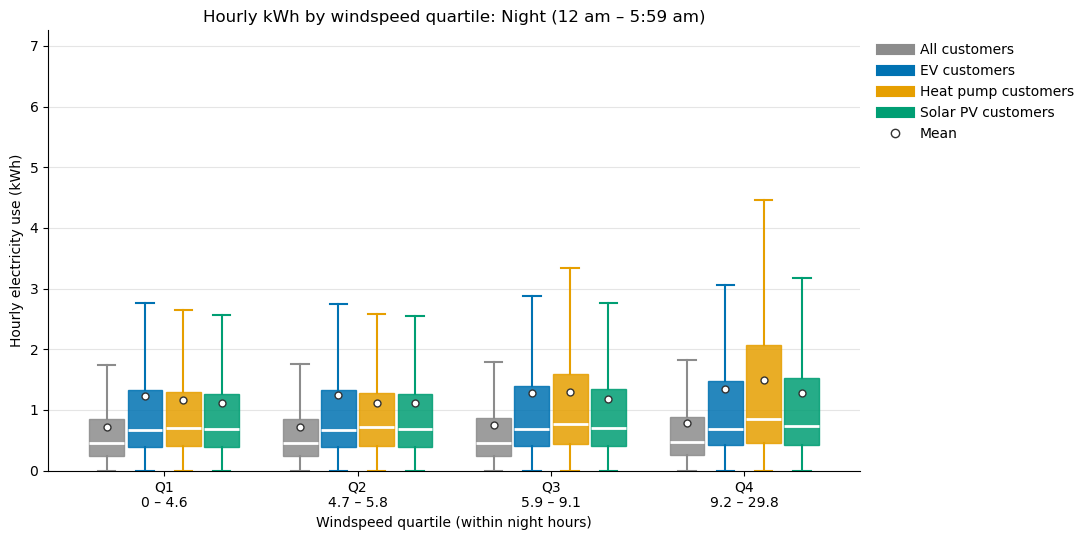

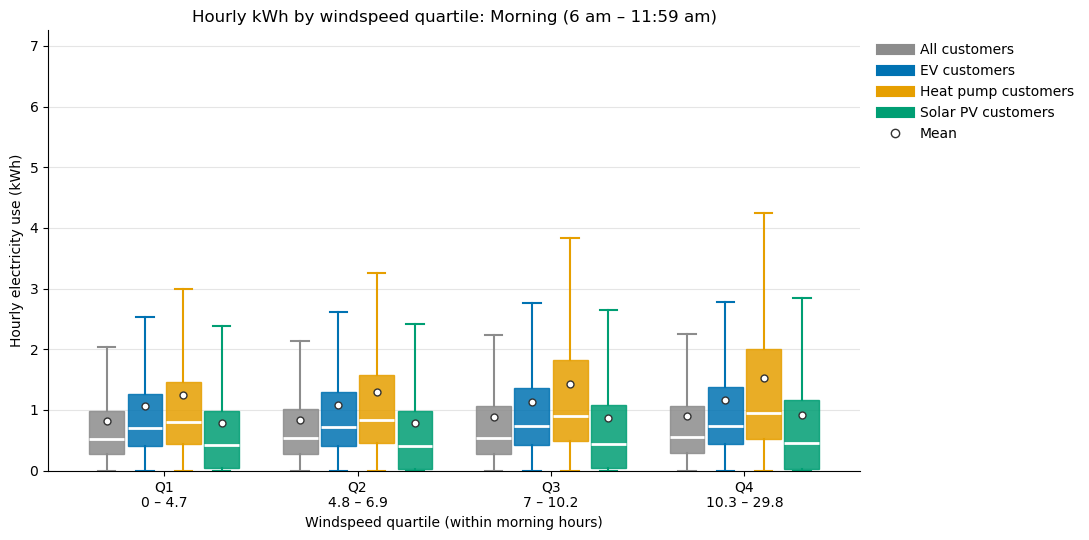

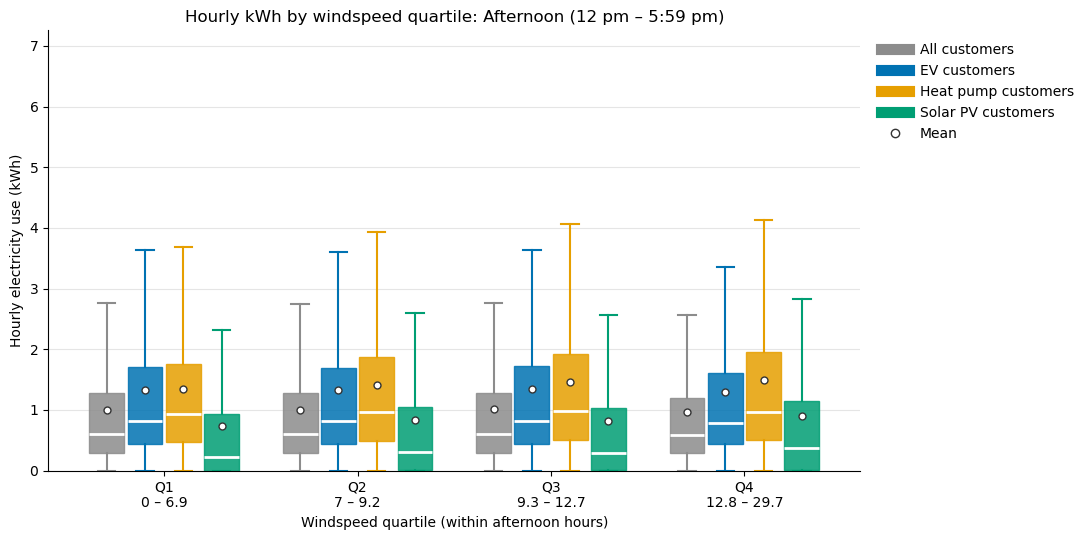

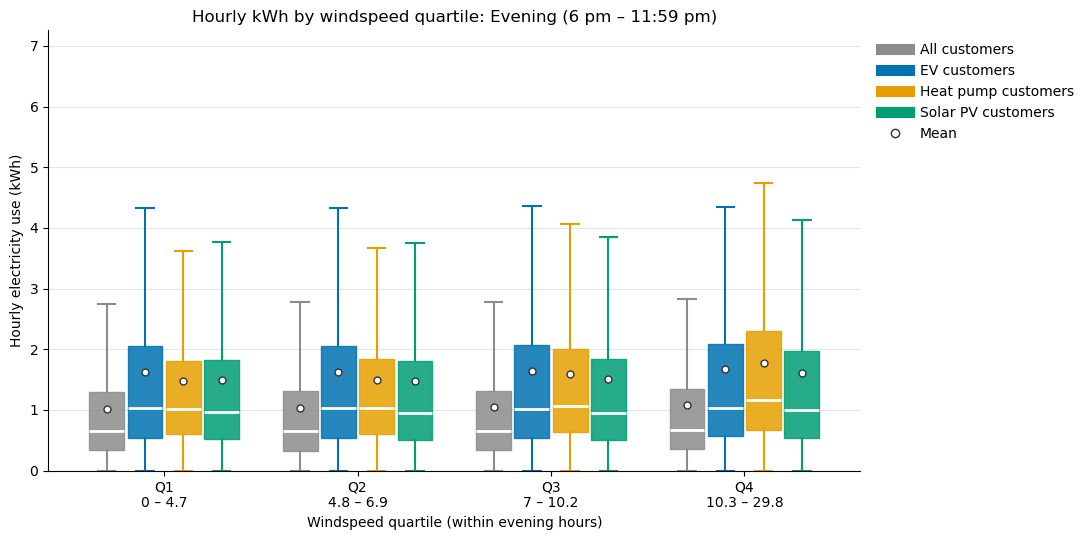

In [10]:
for time_of_day in TIME_OF_DAY_ORDER:
    plot_boxes('windspeed', time_of_day)

In [11]:
con.close()